In [1]:
"""
Visualize agent comparison from bomberman results JSON.
Usage: python compare_agents.py results/xxx.json
"""

import json
import sys
import matplotlib.pyplot as plt
import numpy as np


def load_results(json_path):
    with open(json_path) as f:
        return json.load(f)


def plot_agent_comparison(data, save_path=None):
    agents_data = data['by_agent']
    agents = list(agents_data.keys())

    # metrics to compare
    metrics = ['score', 'coins', 'kills', 'suicides', 'crates', 'invalid']

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()

    colors = plt.cm.Set2(np.linspace(0, 1, len(agents)))

    for idx, metric in enumerate(metrics):
        ax = axes[idx]
        values = [agents_data[a].get(metric, 0) for a in agents]
        bars = ax.bar(range(len(agents)), values, color=colors)
        ax.set_title(metric.upper(), fontsize=12, fontweight='bold')
        ax.set_xticks(range(len(agents)))
        ax.set_xticklabels([a[:15] for a in agents], rotation=30, ha='right', fontsize=8)
        ax.grid(axis='y', alpha=0.3)

        # add value labels on bars
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{val}', ha='center', va='bottom', fontsize=9)

    plt.suptitle('Agent Performance Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches='tight')
        print(f"Saved to {save_path}")
    plt.show()


def print_summary_table(data):
    agents_data = data['by_agent']
    agents = sorted(agents_data.keys(), key=lambda a: -agents_data[a].get('score', 0))

    print("\n" + "="*80)
    print(f"{'AGENT':<25} {'SCORE':>8} {'AVG':>8} {'COINS':>8} {'KILLS':>8} {'SUICIDES':>10}")
    print("="*80)

    for agent in agents:
        d = agents_data[agent]
        rounds = d.get('rounds', 1)
        avg = d.get('score', 0) / rounds
        print(f"{agent[:25]:<25} {d.get('score', 0):>8} {avg:>8.2f} "
              f"{d.get('coins', 0):>8} {d.get('kills', 0):>8} {d.get('suicides', 0):>10}")
    print("="*80 + "\n")


def plot_round_trends(data, window=10, save_path=None):
    """Plot per-round trends: coins collected & suicides over time."""
    rounds_data = data['by_round']
    round_keys = sorted(rounds_data.keys())

    coins  = [rounds_data[k]['coins']    for k in round_keys]
    kills  = [rounds_data[k]['kills']    for k in round_keys]
    sui    = [rounds_data[k]['suicides'] for k in round_keys]
    steps  = [rounds_data[k]['steps']    for k in round_keys]

    def moving_avg(x, w):
        return np.convolve(x, np.ones(w)/w, mode='valid')

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    axes[0, 0].plot(coins, alpha=0.3, color='orange')
    axes[0, 0].plot(range(window-1, len(coins)), moving_avg(coins, window),
                    linewidth=2, color='darkorange')
    axes[0, 0].set_title('Coins collected per round')
    axes[0, 0].grid(alpha=0.3)

    axes[0, 1].plot(kills, alpha=0.3, color='red')
    axes[0, 1].plot(range(window-1, len(kills)), moving_avg(kills, window),
                    linewidth=2, color='darkred')
    axes[0, 1].set_title('Kills per round')
    axes[0, 1].grid(alpha=0.3)

    axes[1, 0].plot(sui, alpha=0.3, color='purple')
    axes[1, 0].plot(range(window-1, len(sui)), moving_avg(sui, window),
                    linewidth=2, color='indigo')
    axes[1, 0].set_title('Suicides per round')
    axes[1, 0].grid(alpha=0.3)

    axes[1, 1].plot(steps, alpha=0.3, color='blue')
    axes[1, 1].plot(range(window-1, len(steps)), moving_avg(steps, window),
                    linewidth=2, color='darkblue')
    axes[1, 1].set_title('Steps per round (max 400)')
    axes[1, 1].grid(alpha=0.3)

    plt.suptitle(f'Per-round trends (moving avg window={window})',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches='tight')
        print(f"Saved to {save_path}")
    plt.show()




AGENT                        SCORE      AVG    COINS    KILLS   SUICIDES
feature_is_everything          558     5.58      353       41         10
my_agent3                      506     5.06      306       40         20
rule_based_agent               371     3.71      166       41         53
peaceful_agent                   2     0.02        2        0          0

Saved to agent_comparison.png


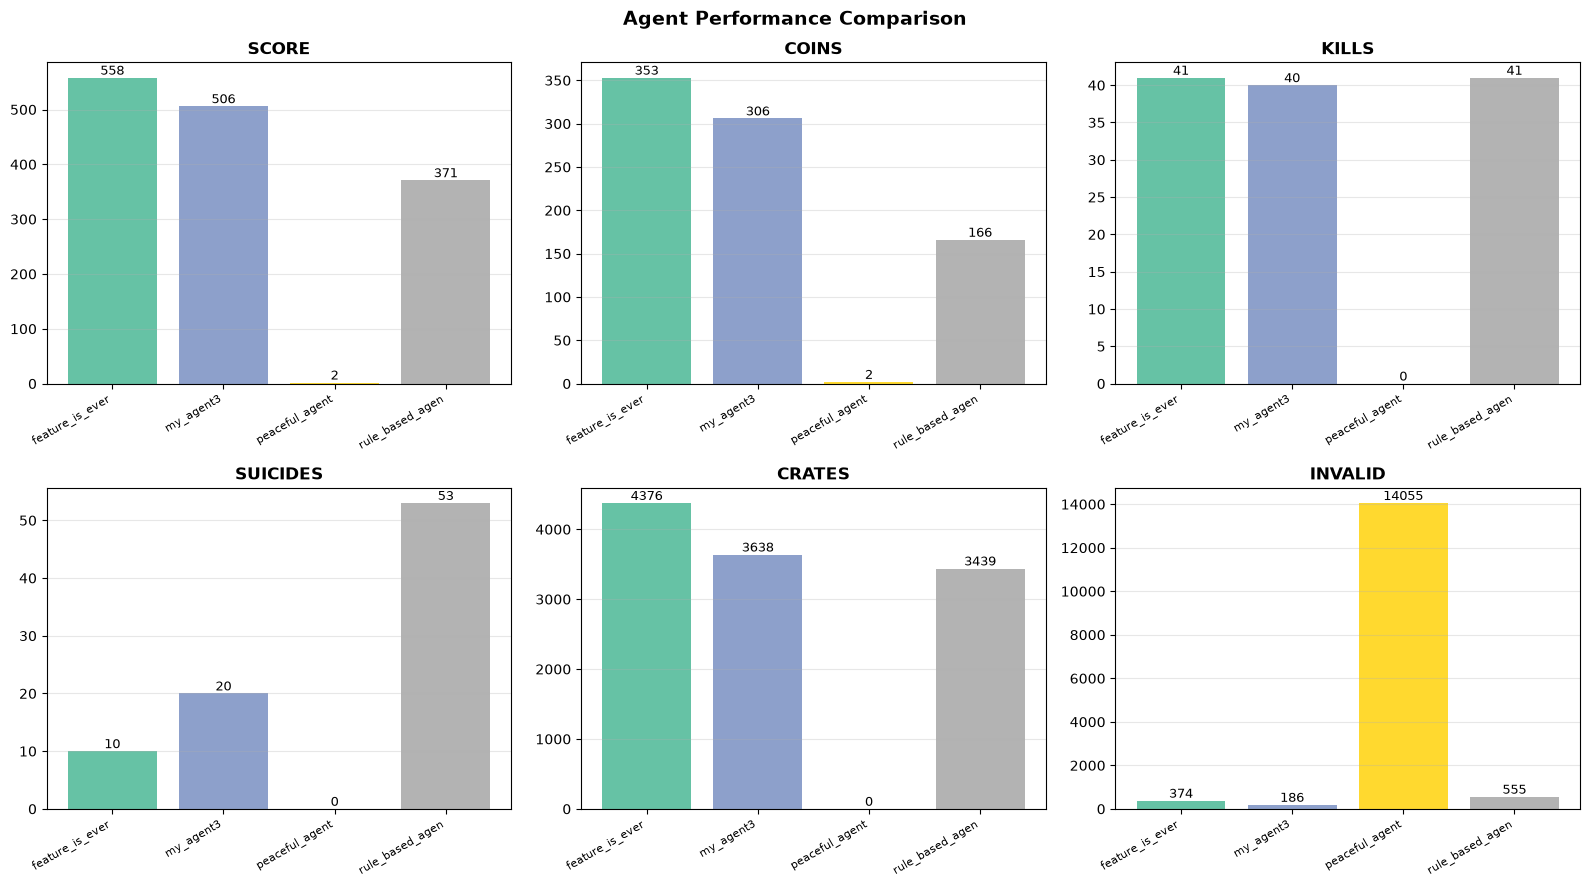

Saved to round_trends.png


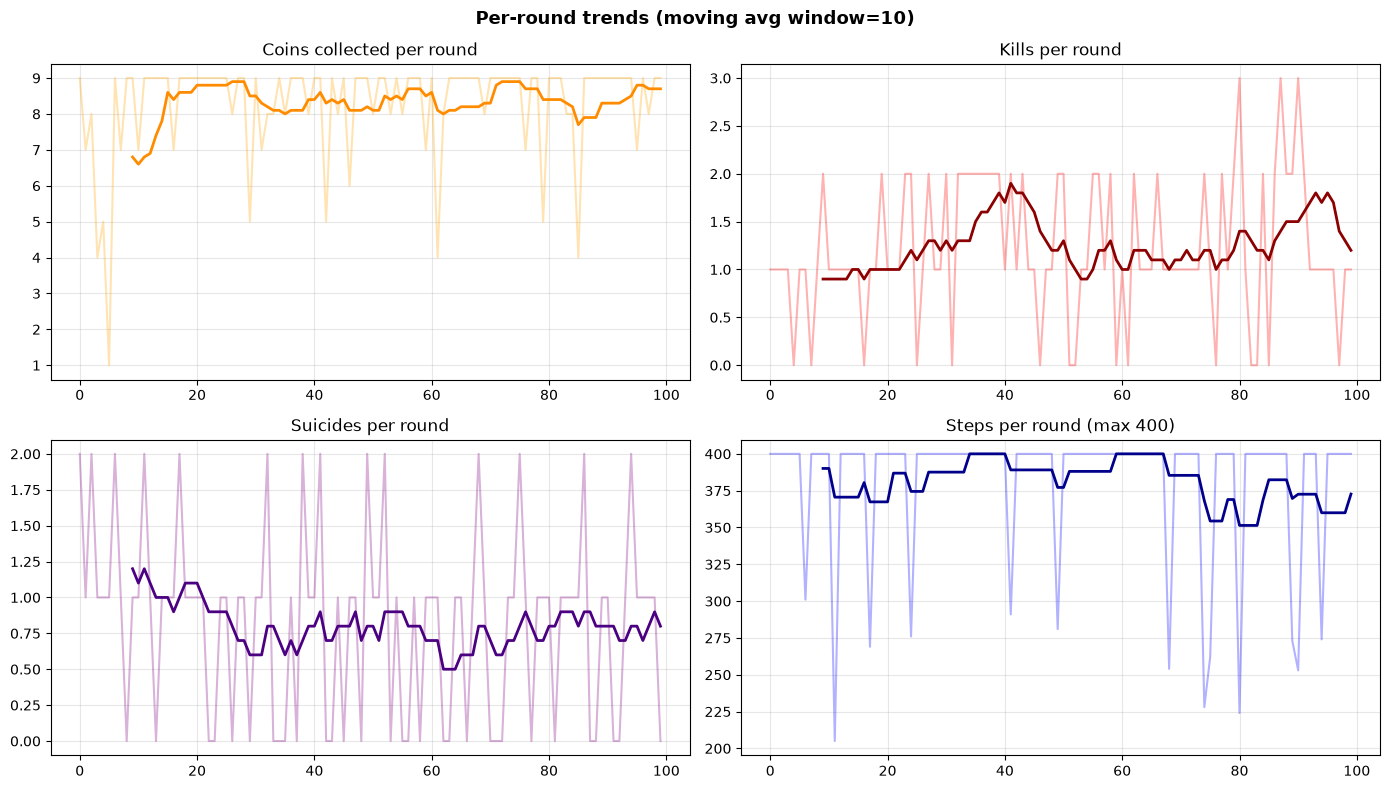

In [3]:
json_path = "../results/2026-08-24 18-07-33.json"

data = load_results(json_path)
print_summary_table(data)
plot_agent_comparison(data, save_path='agent_comparison.png')
plot_round_trends(data, window=10, save_path='round_trends.png')